# CSC 349A Numerical Analysis - Lecture 9 - Newton-Raphson Method
In this lecture we introduce the Newton/Raphson method
for root finding as an example of an open method (i.e requires only an
initial estimate of the root) in contrast to bracketing methods like
Bisection which require an interval to bound the root. This included two derivations 
of the algorithm, an example of the algorithm and analysis of the error convergence.
The exact details are provided below.

## Newton-Raphson
The real roots of a function $f(x)$ occur when the graph of the
function intersects with the x-axis. The main idea behind the
Newton-Raphson method for root finding is given an initial
approximation $x_0$ to a zero of $f(x)$ to approximate the graph of $f(x)$
at $x_0$ by the **tangent line** - essentially linearizing the function in
that area. 

Let $x_1$, the intersection of the tangent line with the $x$-axis, be
the next approximation to $x_t$. The slope of the tangent line is: 

\begin{equation}
f'(x_0)=\frac{f(x_0)-0}{x_0-x_1} 
\end{equation} 

Thus the tangent line intersects the $x$-axis when

\begin{equation} 
f'(x_0)(x_0-x_1) = f(x_0)
\end{equation}  

so the next estimate $x_1$ can be calculated as: 

\begin{equation} 
x_{1} = x_{0} - \frac{f(x_0)}{f'(x_0)}
\end{equation}

The process can be repeated starting from the new root estimate $x_1$
with the following equation. 

\begin{equation} 
x_2 = x_1 - \frac{f(x_1)}{f'(x_1)}
\end{equation}

The figure below shows this visually. 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(0,9,0.1)
fx = 0.5 * x**3 - 64
plt.plot(x,fx)
x0=3
fx0 = 0.5 * x0**3 - 64
x1 = x0 - fx0/(1.5 * x0**2)
plt.plot([x0,x1],[fx0,0],'--')
plt.plot(x, np.zeros(x.size))
plt.plot(x0,0,'*')
plt.text(x0,-10,'x0')
plt.plot(x0,fx0, '*')
plt.text(x0,fx0-10, 'f(x0)')
plt.text(x1,-10,'x1')
fx1 = 0.5 * x1**3 - 64
x2 = x1 - fx1/(1.5 * x1**2)
plt.plot(x2,0,'*')
plt.text(x2,-10,'x2')
plt.plot([x1,x2],[fx1,0],'--')
plt.plot(x1,fx1,'*')
plt.text(x1,fx1-10, 'f(x1)')
plt.show()

In general, we calculate a new root estimate $x_{i+1}$ from the previous estimate
$x_i$ with the following equation. 

\begin{equation} 
x_{i+1} = x_i - \frac{f(x_i)}{f'(x_i)}
\end{equation} 


## Example of Newton-Raphson Method
Estimate the root of $f(x) = e^{-x} -x$ employing an initial guess of
$x_0 = 0$. 

Note that $x_t$ = 0.56714329... is the actual root. Also, $f'(x) = -e^{-x} - 1$ and thus

\begin{equation}
x_{i+1} = x_i - \frac{e^{-x_i} - x_i}{-e^{-x_i}-1}
\end{equation}

This iterative equation can be applied to compute: 

| $i$ | $x_i$ | $\varepsilon_t(\%)$ | 
|:---:|:----------:|:------------:|
| $0$ | $0$ | $100$ |
| $1$ | $0.5$ | $11.8$ | 
| $2$ | $0.566311003$ | $0.147$ |
| $3$ | $0.567143165$ | $0.0000220$ | 
| $4$ | $0.567143290$ | $<10^{-8}$ |  
 
Notice that the approach rapidly converges on the true root much faster than 
it would using *Bisection*. 

## Newton method convergence
Consider the Taylor theorem for $f(x)$ with $n=1$ expanded about
$x_i$ (i.e $a = x_i$): 

\begin{equation} 
f(x) = f(x_i) + (x-x_i) f'(x_i) + \frac{f''(\xi)}{2}(x-x_i)^2
\end{equation}

for some value $\xi$ between $x$ and $x_i$. 

The derivation of the Newton-Raphson method gives insight into how
fast Newton's method converges:

First we evaluate the Taylor Theorem at $x=x_t$, an exact zero: 

\begin{equation} 
0 = f(x_t) = f(x_i) + (x_t-x_i)f'(x_i) + \frac{(x_t-x_i)^2}{2}f''(\xi)
\end{equation} 

Newton's method $x_{i+1} = x_{i} - \frac{f(x_i)}{f'(x_i)}$ can be rewritten as: 

\begin{equation} 
0 = f(x_i) + (x_{i+1} -x_{i}) f'(x_{i})
\end{equation} 

If we subtract the last two equations then we get: 

\begin{equation} 
0 = (x_t -x_{i+1}) f'(x_i) + \frac{(x_t - x_i)^2}{2}f''(\xi)
\end{equation} 

or if we let $E_{i+1} = x_t - x_{i+1}$ and $E_i = x_t - x_{i}$ denote the error in $x_{i+1}, x_i$ then we have: 

\begin{equation} 
0 = E_{i+1} f'(x_i) + \frac{E_i^2}{2} f''(\xi) 
\end{equation} 

Thus: 

\begin{equation} 
\frac{E_{i+1}}{E_i^2} = \frac{-f''(\xi)}{2f'(x_{i})} 
\end{equation} 

which relates $E_{i+1}$ to $E_i$. 

**Definition (not in textbook)** 
If a sequence ${x_0, x_1, x_2, x_3, \dots }$ converges to $x_t$ that is 
$\lim_{i \rightarrow \infty}x_i = x_t$ and $E_i = x_t - x_i$, then the order of converge of the sequence is $\alpha$ if there are constants $\lambda > 0$ and $\alpha \geq 1$ such that: 

\begin{equation} 
\lim_{i \rightarrow \infty} \frac{|E_{i+1}|}{|E_i|^{\alpha}} = \lambda 
\end{equation} 

In general, $\lambda$ and $\alpha$ depend on the algorithm used to compute ${x_i}$, on $f(x)$, and on the multiplicity of the zero $x_t$. 

**Most common case:**
 
$\alpha = 1$ linear convergence

For large $i$, $|E_{i+1}| \approx \lambda |E_i|$

In this case, successive errors decrease approximately by a constant amount: 

\begin{eqnarray*} 
|E_{i+1}| &\approx & \lambda |E_i| \\ 
|E_{i+2}| &\approx &  \lambda |E_{i+1}| \approx \lambda^2 |E_i|\\ 
|E_{i+3}| & \approx &  \lambda |E_{i+2}| \approx \lambda^3 |E_i|\\ 
\mbox{etc} \\ 
\end{eqnarray*} 

Errors $|E_{i+1}| \rightarrow 0$, that is $\lim_{i \rightarrow \infty}
x_i = x_t$ only if $0 < \lambda < 1$.

For $\alpha = 2$ we have quadratic convergence. 

For large $i$, $|E_{i+1}| \approx \lambda |E_i|^2$ 

Meaning: after some error $|E_i| < 1$, convergence is rapid as the number of correct significant digits approximately doubles with each iteration e.g if $|E_i| = 10^{-t}$, then $|E_{i+1}| \approx \lambda 10^{-2t}$. 

For Newton's method above: 

$$
\frac{E_{i+1}}{E_{i}^2} = \frac{-f''(\xi)}{2f'(x_i)} 
$$

for some $\xi$ between $x_i$ and $x_{i+1}$. 

$$
\lim_{i \rightarrow \infty} \frac{|E_{i+1}|}{|E_i|^2} = \lim_{i \rightarrow \infty} 
\frac{|f''(\xi)|}{2|f'(x_i)|} = \frac{|f''(x_t)|}{2|f'(x_t)|}
$$

which is a constant $\lambda$ provided that $f'(x_t) \neq 0$. 

## Implementation
The algorithm for Newton's method can be written in Python as
follows: 

In [12]:
def Newton(x0, eps, imax, f, fp):
    i=1
    print(' iteration approximation \n')
    print('{:6.0f} {:18.16f}\n'.format(0,x0))
    while i <= imax:
        root = x0 - f(x0)/fp(x0)
        print('{:6.0f} {:18.16f}\n'.format(i,root))
        fr = f(root)
        if (fr == 0) or (abs(1-x0/root) < eps):
            return root
        i = i + 1
        x0 = root
    print( ' failed to converge in ',imax,' iterations\n')

Note that in general, using $|f(root)| < \varepsilon$ is not a suitable
test for convergence (instead of testing approximation error). The
reason is that $|f(root)| < \varepsilon$ does not imply that the value
*root* is within distance of $\varepsilon$ of an exact root $x_t$. 

## Quadratic convergence of Newton's method
{\bf Theorem}: If Newton's method is applied to $f(x) = 0$ producing 
a sequence $x_i$ that converges to a root $x_t$, and if $f'(x_t) \neq 0$, then 
then order of convergence is $2$. 

If $f'(x_t) = 0$ and Newton's method convergences to a root $x_t$, then we will see later that the order of convergence is NOT quadratic.

**Example 1** An illustration of the quadratic convergence of Newton's method. Here $f(x) = cos(x) -x$. 

In [ ]:
def Ex1(x):
    return np.cos(x) - x
    
def Ex1Prime(x):
    return -(np.sin(x)) - 1
    
xa = Newton(np.pi/4,10**(-8),1000,Ex1,Ex1Prime)

Here, at most 16 correct digits are possible. The table below summarizes the above results, where the bold digits are all correct. 

| $i$ | $x_i$ | no. of correct digits |
|:---:|:---------------------|:----------------------:|
|0   | $\frac{\pi}{4}$ = 0.**7**85398 | 1 |
|1   | 0.**739**5361 | 3 | 
|2   | 0.**7390851**78 | 7 |
|3   | 0.**73908513321516**10 | 14 | 
|4   | 0.**7390851332151606**  | 16 | 

**Example 2** The following illustrates the possible effect of a poor initial approximation with Newton's method, yet the eventual characteristic quadratic convergence. Here Newton's method is used to compute a root of $x^3 + 4 x^2 -10 = 0$ with $x_0 = -100$.

In [ ]:
def Ex2(x):
    return x**3 + 4 * x**2 - 10
    
def Ex2Prime(x):
    return 3 * x**2 + 8 * x
    
xa = Newton(-100,10**(-8),1000,Ex2,Ex2Prime)

Notice how the convergence rate actually looks linear for the first 20 iterations in this example. This reitereates that the quadratic
convergence only occurs once we get close to the actual root. If your first approximation is far away then the convergence is not 
entirely quadratic.

Your text illustrates four cases where Newton has poor convergence or divergence. I have inserted it here as well.

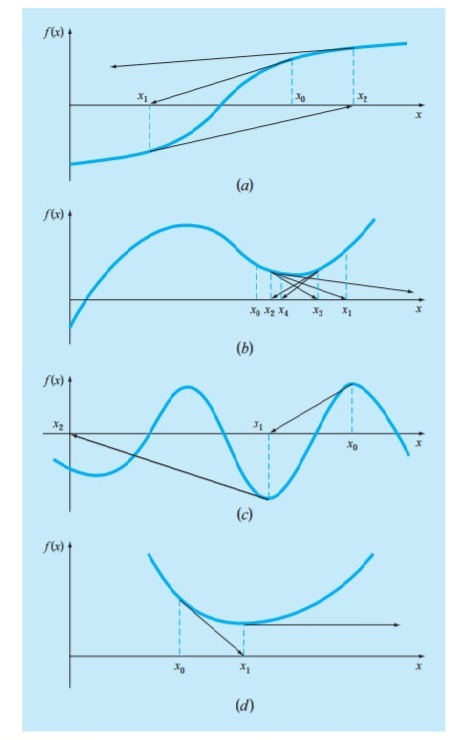

**Theorem** Suppose that $f(x),f'(x)$ and $f''(x)$ all exist and are continuous on some interval $[a,b]$, that $x_t \in [a,b]$ is a root of $f(x) = 0$, and that $f'(x_t) \neq 0$. Then there exists a value $\delta > 0$, such that Newton's method converges for all initial approximations $x_0 \in [x_t - \delta, x_t + \delta]$. 

**Note** that in general there is no way to determine such a value $\delta$. This theorem only says that for all such functions $f(x)$, such a value $\delta$ exists. Even if the value of $\delta$ is extremely small, there is an interval of values around the root $x_t$ such that if $x_0$ (the initial approximation) lies in this interval, then Newton's method will converge. 

Thus the interpretation of the above theorem is that Newton's method always converges if the initial approximation $x_0$ is sufficiently close to the root $x_t$. 


## Appendix
Sir Isaac Newton (1642-1726) - During much of 1665-1666, immediately after Newton had earned
his degree from Trinity College, Cambridge, the college was closed due to the black plague. Newton
went home to live and think during those two years. The result was the most productive period of
mathematical discovery ever reported. During that time he made four of his greatest mathematical
discoveries: (1) the binomial theorem, (2) calculus, (3) the law of gravity, and (4) the colour spectrum.

While Newton needs no introduction I was always curious about who
Raphson was. I was under the mistaken impression that he was some
mathematician in the 20th century who "re-discovered" Newton's
method. It turns out that's not the case. He was relatively a
contemporary of Newton and a member of the famous Royal Philosophical
Society. He supported Newton's claim to the invention of calculus in the
famous debate between Newton and Leibnitz about who invented
first. One tidbit of minor information that I found particularly
interesting was that he also was known for translating one of Newton's
books into English. It is easy to forget that at the time all
scientific communication was still conducted in Latin even though
Latin was a language that had not been spoken for centuries.